# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Marcelia Devi Sumita Br Tarigan S
- **Email:** Marceliatarigans23@gmail.com
- **ID Dicoding:** DS200B6X0962

In [11]:
import zipfile
import os

zip_path = '/content/Bike-sharing-dataset.zip'
extract_path = '/content/data'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print(os.listdir(extract_path))


Dataset berhasil diekstrak!
['day.csv', 'Readme.txt', 'hour.csv']


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

### Penerapan SMART pada Pertanyaan Bisnis

**Pertanyaan 1: Pola Penyewaan Berdasarkan Waktu**

Bagaimana pola rata-rata jumlah penyewaan sepeda berdasarkan jam dalam sehari dan perbedaan antara hari kerja (working day) dengan hari non-kerja (non-working day) selama periode Januari 2011–Desember 2012, serta kapan waktu dengan permintaan tertinggi dan terendah sebagai dasar penentuan waktu prioritas penyediaan sepeda?

keterangan:

- **Specific:** Berfokus pada pola rata-rata penyewaan sepeda berdasarkan jam dalam sehari serta perbedaan antara hari kerja (*working day*) dan hari non-kerja (*non-working day*).
- **Measurable:** Diukur menggunakan rata-rata jumlah penyewaan sepeda (*cnt*) berdasarkan jam dan jenis hari untuk mengidentifikasi waktu dengan permintaan tertinggi dan terendah.
- **Action-Oriented:** Hasil analisis dapat digunakan untuk menentukan waktu prioritas penyediaan dan distribusi sepeda.
- **Relevant:** Berkaitan dengan kebutuhan pengelola Bike Sharing dalam mengoptimalkan ketersediaan sepeda sesuai pola permintaan pengguna.
- **Time-Bound:** Menggunakan data penyewaan sepeda selama Januari 2011 hingga Desember 2012.

**Pertanyaan 2: Pola Penyewaan Berdasarkan Musim dan Cuaca**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode Januari 2011–Desember 2012, serta kondisi mana yang menunjukkan permintaan tertinggi dan terendah sebagai dasar penyusunan strategi operasional berdasarkan perubahan musim dan cuaca?

keterangan:


- **Specific:** Berfokus pada perbedaan rata-rata penyewaan sepeda berdasarkan musim dan kondisi cuaca serta kombinasi keduanya.
- **Measurable:** Diukur menggunakan rata-rata jumlah penyewaan sepeda (*cnt*) berdasarkan kategori musim, kondisi cuaca, dan kombinasi musim dengan cuaca.
- **Action-Oriented:** Hasil analisis dapat digunakan sebagai pertimbangan dalam menyesuaikan kesiapan dan distribusi armada berdasarkan perubahan musim dan kondisi cuaca.
- **Relevant:** Berkaitan dengan kebutuhan pengelola Bike Sharing dalam mengantisipasi perubahan permintaan akibat variasi musim dan cuaca.
- **Time-Bound:** Menggunakan data penyewaan sepeda selama Januari 2011 hingga Desember 2012.


## Import Semua Packages/Library yang Digunakan

In [12]:

# Import library untuk pengolahan data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Import library untuk pengolahan file
import zipfile
import os

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")


## Data Wrangling

### Gathering Data

Dataset yang digunakan dalam proyek ini adalah **Bike Sharing Dataset** yang diperoleh dari UCI Machine Learning Repository.

Dataset ini berisi catatan penyewaan sepeda pada sistem Capital Bikeshare selama periode Januari 2011 hingga Desember 2012. Dataset terdiri atas dua file utama, yaitu:

1. **day.csv**: Data penyewaan sepeda berdasarkan agregasi harian.
2. **hour.csv**: Data penyewaan sepeda berdasarkan agregasi per jam.

Kedua dataset digunakan karena memiliki tingkat granularitas berbeda sehingga dapat mendukung analisis pola penyewaan berdasarkan waktu, jenis hari, musim, dan kondisi cuaca.

Sumber dataset: [UCI Machine Learning Repository – Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)

In [13]:
import zipfile
import os

zip_path = '/content/Bike-sharing-dataset.zip'
extract_path = '/content/data'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print(os.listdir(extract_path))

Dataset berhasil diekstrak!
['day.csv', 'Readme.txt', 'hour.csv']


#### Load df ...

In [14]:
# Load Dataset Bike Sharing

import pandas as pd

day_df = pd.read_csv('/content/data/day.csv')
hour_df = pd.read_csv('/content/data/hour.csv')

print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)

display(day_df.head())
display(hour_df.head())

Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**

- Dataset `day.csv` memiliki 731 baris dan 16 kolom yang merepresentasikan data penyewaan sepeda harian selama periode Januari 2011–Desember 2012.
- Dataset `hour.csv` memiliki 17.379 baris dan 17 kolom yang merepresentasikan data penyewaan sepeda berdasarkan jam selama periode yang sama.
- Kedua dataset memiliki tingkat granularitas yang berbeda. Dataset `day.csv` dapat digunakan untuk mengidentifikasi pola penyewaan secara harian, termasuk variasi berdasarkan musim dan kondisi cuaca. Sementara itu, dataset `hour.csv` memungkinkan analisis yang lebih terperinci mengenai pola penyewaan berdasarkan jam serta perbedaan antara hari kerja (*working day*) dan hari non-kerja (*non-working day*).
- Penggunaan kedua dataset secara bersamaan memberikan gambaran yang lebih menyeluruh mengenai karakteristik permintaan penyewaan sepeda, baik berdasarkan pola waktu maupun kondisi lingkungan.

### Assessing Data

#### Identifying ... problem

In [15]:

# 1. PEMERIKSAAN STRUKTUR DATA

print("STRUKTUR DATA DAY.CSV")
day_df.info()

print("\nSTRUKTUR DATA HOUR.CSV")
hour_df.info()

# 2. PEMERIKSAAN MISSING VALUES

print("\nMISSING VALUES DAY.CSV")
print(day_df.isnull().sum())

print("\nMISSING VALUES HOUR.CSV")
print(hour_df.isnull().sum())

# 3. PEMERIKSAAN DUPLICATE DATA

print("\nDUPLIKASI DAY.CSV:", day_df.duplicated().sum())
print("DUPLIKASI HOUR.CSV:", hour_df.duplicated().sum())

# 4. STATISTIK DESKRIPTIF

print("\nSTATISTIK DESKRIPTIF DAY.CSV")
display(day_df.describe())

print("\nSTATISTIK DESKRIPTIF HOUR.CSV")
display(hour_df.describe())

# 5. PEMERIKSAAN NILAI KATEGORIK

categorical_columns = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit'
]

print("\nNILAI UNIK VARIABEL KATEGORIK")

for col in categorical_columns:
    print(f"\n{col}:")
    print("day.csv:", sorted(day_df[col].dropna().unique()))
    print("hour.csv:", sorted(hour_df[col].dropna().unique()))

# 6. PEMERIKSAAN KONSISTENSI JUMLAH SEWA

print("\nKONSISTENSI JUMLAH PENYEWAAN")

print(
    "Ketidaksesuaian day.csv:",
    (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum()
)

print(
    "Ketidaksesuaian hour.csv:",
    (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum()
)


# 7. PEMERIKSAAN RENTANG JAM

print("\nRENTANG JAM HOUR.CSV")
print("Jam minimum:", hour_df['hr'].min())
print("Jam maksimum:", hour_df['hr'].max())


# 8. PEMERIKSAAN FORMAT TANGGAL

print("\nPEMERIKSAAN TANGGAL")

for name, df in [('day.csv', day_df), ('hour.csv', hour_df)]:
    dates = pd.to_datetime(df['dteday'], errors='coerce')

    print(f"\n{name}")
    print("Tanggal tidak valid:", dates.isna().sum())
    print("Tanggal paling awal:", dates.min())
    print("Tanggal paling akhir:", dates.max())


STRUKTUR DATA DAY.CSV
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

STRUKTUR DATA HOUR.CSV
<class 'pandas.core.frame.DataFrame'>
RangeInde

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



STATISTIK DESKRIPTIF HOUR.CSV


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



NILAI UNIK VARIABEL KATEGORIK

season:
day.csv: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
hour.csv: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

yr:
day.csv: [np.int64(0), np.int64(1)]
hour.csv: [np.int64(0), np.int64(1)]

mnth:
day.csv: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
hour.csv: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

holiday:
day.csv: [np.int64(0), np.int64(1)]
hour.csv: [np.int64(0), np.int64(1)]

weekday:
day.csv: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
hour.csv: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

workingday:
day.csv: [np.int64(0), np.int64(1)]
hour.csv: [np.int64(0), np.int64(1)]

weathersit:
day.csv: [np.int

In [16]:

# PEMERIKSAAN OUTLIER DENGAN METODE IQR

def check_outlier(df, dataset_name, columns):
    print(f"\nPEMERIKSAAN OUTLIER {dataset_name}")

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        ]

        print(f"\nVariabel: {col}")
        print("Batas bawah:", round(lower_bound, 2))
        print("Batas atas:", round(upper_bound, 2))
        print("Jumlah kandidat outlier:", len(outliers))


# Pemeriksaan jumlah penyewaan
check_outlier(
    day_df,
    "DAY.CSV",
    ['casual', 'registered', 'cnt']
)

check_outlier(
    hour_df,
    "HOUR.CSV",
    ['casual', 'registered', 'cnt']
)


# PEMERIKSAAN RENTANG VARIABEL CUACA

weather_columns = ['temp', 'atemp', 'hum', 'windspeed']

for name, df in [('day.csv', day_df), ('hour.csv', hour_df)]:
    print(f"\nPEMERIKSAAN RENTANG {name}")

    for col in weather_columns:
        invalid = ((df[col] < 0) | (df[col] > 1)).sum()
        print(f"{col}: {invalid} nilai di luar rentang 0-1")



PEMERIKSAAN OUTLIER DAY.CSV

Variabel: casual
Batas bawah: -855.25
Batas atas: 2266.75
Jumlah kandidat outlier: 44

Variabel: registered
Batas bawah: -922.25
Batas atas: 8195.75
Jumlah kandidat outlier: 0

Variabel: cnt
Batas bawah: -1054.0
Batas atas: 10162.0
Jumlah kandidat outlier: 0

PEMERIKSAAN OUTLIER HOUR.CSV

Variabel: casual
Batas bawah: -62.0
Batas atas: 114.0
Jumlah kandidat outlier: 1192

Variabel: registered
Batas bawah: -245.0
Batas atas: 499.0
Jumlah kandidat outlier: 680

Variabel: cnt
Batas bawah: -321.5
Batas atas: 642.5
Jumlah kandidat outlier: 505

PEMERIKSAAN RENTANG day.csv
temp: 0 nilai di luar rentang 0-1
atemp: 0 nilai di luar rentang 0-1
hum: 0 nilai di luar rentang 0-1
windspeed: 0 nilai di luar rentang 0-1

PEMERIKSAAN RENTANG hour.csv
temp: 0 nilai di luar rentang 0-1
atemp: 0 nilai di luar rentang 0-1
hum: 0 nilai di luar rentang 0-1
windspeed: 0 nilai di luar rentang 0-1


**Steps to Take:**

Berdasarkan hasil pemeriksaan kualitas data, beberapa tindakan yang dilakukan pada tahap Cleaning Data adalah sebagai berikut:

1. **Penyesuaian tipe data tanggal**

   Kolom `dteday` pada kedua dataset masih memiliki tipe data `object`. Oleh karena itu, kolom tersebut dikonversi menjadi tipe `datetime` agar dapat digunakan dalam analisis berbasis waktu.

2. **Pelabelan variabel kategorik**

   Variabel seperti `season`, `weathersit`, `weekday`, `yr`, dan `mnth` masih direpresentasikan menggunakan kode numerik. Untuk memudahkan interpretasi, dilakukan penambahan kolom label kategori tanpa mengubah nilai kode aslinya.

3. **Evaluasi kandidat outlier**

   Pemeriksaan menggunakan metode Interquartile Range (IQR) menunjukkan adanya kandidat outlier pada variabel jumlah penyewaan. Kandidat tersebut tidak langsung dihapus karena nilai ekstrem dapat mencerminkan variasi permintaan yang sebenarnya. Oleh karena itu, nilai tetap dipertahankan dengan mempertimbangkan karakteristik data.

4. **Verifikasi kualitas data lainnya**

   Pemeriksaan missing values, duplicate data, validitas tanggal, rentang variabel, dan konsistensi jumlah penyewaan dilakukan untuk memastikan data layak digunakan dalam analisis selanjutnya.

**Insight:**

Berdasarkan hasil pemeriksaan kualitas data, diperoleh beberapa temuan sebagai berikut:

1. **Struktur data:** Dataset `day.csv` memiliki 731 baris dan 16 kolom, sedangkan `hour.csv` memiliki 17.379 baris dan 17 kolom. Kedua dataset memiliki granularitas berbeda sehingga dapat digunakan untuk analisis harian dan per jam.

2. **Kelengkapan data:** Tidak ditemukan missing values pada kedua dataset. Dengan demikian, tidak diperlukan penanganan nilai kosong.

3. **Duplikasi data:** Tidak ditemukan baris duplikat pada kedua dataset sehingga seluruh observasi dapat dipertahankan.

4. **Validitas variabel:** Nilai variabel kategorik berada pada rentang kode yang sesuai. Variabel jam pada `hour.csv` juga memiliki rentang valid, yaitu 0–23.

5. **Konsistensi data penyewaan:** Tidak ditemukan ketidaksesuaian antara jumlah penyewaan total (`cnt`) dengan penjumlahan pengguna casual dan registered pada kedua dataset.

6. **Validitas tanggal:** Tidak ditemukan tanggal yang gagal dikonversi. Kedua dataset mencakup periode 1 Januari 2011 hingga 31 Desember 2012. Namun, kolom `dteday` masih bertipe object sehingga perlu dikonversi menjadi datetime.

7. **Kandidat outlier:** Pemeriksaan statistik deskriptif dan metode IQR menunjukkan adanya kandidat outlier pada variabel jumlah penyewaan. Nilai tersebut perlu dievaluasi lebih lanjut dan tidak langsung dihapus karena dapat merepresentasikan variasi permintaan yang sebenarnya.

Secara keseluruhan, kedua dataset memiliki kualitas yang baik dan layak digunakan untuk analisis lebih lanjut, dengan beberapa penyesuaian tipe data dan pelabelan variabel kategorik pada tahap data cleaning.

### Cleaning Data

#### Fixing ... problem

In [17]:

# 1. KONVERSI TIPE DATA TANGGAL

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. MEMBUAT LABEL VARIABEL KATEGORIK

# Label musim
season_labels = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

# Label kondisi cuaca
weather_labels = {
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}

# Label hari
weekday_labels = {
    0: 'Sunday',
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday'
}

# Label tahun
year_labels = {
    0: '2011',
    1: '2012'
}

# Label bulan
month_labels = {
    1: 'January',
    2: 'February',
    3: 'March',
    4: 'April',
    5: 'May',
    6: 'June',
    7: 'July',
    8: 'August',
    9: 'September',
    10: 'October',
    11: 'November',
    12: 'December'
}


# Menerapkan label pada kedua dataset
for df in [day_df, hour_df]:

    df['season_label'] = df['season'].map(season_labels)
    df['weather_label'] = df['weathersit'].map(weather_labels)
    df['weekday_label'] = df['weekday'].map(weekday_labels)
    df['year_label'] = df['yr'].map(year_labels)
    df['month_label'] = df['mnth'].map(month_labels)


# 3. MEMERIKSA HASIL CLEANING

print("Tipe data tanggal setelah cleaning:")
print("day.csv:", day_df['dteday'].dtype)
print("hour.csv:", hour_df['dteday'].dtype)

print("\nPemeriksaan missing value setelah pelabelan:")
print("day.csv:", day_df.isnull().sum().sum())
print("hour.csv:", hour_df.isnull().sum().sum())

print("\nContoh hasil pelabelan:")
display(
    day_df[
        ['dteday', 'season', 'season_label',
         'weathersit', 'weather_label']
    ].head()
)

display(
    hour_df[
        ['dteday', 'hr', 'weekday_label',
         'season_label', 'weather_label']
    ].head()
)


Tipe data tanggal setelah cleaning:
day.csv: datetime64[ns]
hour.csv: datetime64[ns]

Pemeriksaan missing value setelah pelabelan:
day.csv: 0
hour.csv: 0

Contoh hasil pelabelan:


,dteday,season,season_label,weathersit,weather_label
0,2011-01-01,1,Spring,2,Mist/Cloudy
1,2011-01-02,1,Spring,2,Mist/Cloudy
2,2011-01-03,1,Spring,1,Clear
3,2011-01-04,1,Spring,1,Clear
4,2011-01-05,1,Spring,1,Clear


,dteday,hr,weekday_label,season_label,weather_label
0,2011-01-01,0,Saturday,Spring,Clear
1,2011-01-01,1,Saturday,Spring,Clear
2,2011-01-01,2,Saturday,Spring,Clear
3,2011-01-01,3,Saturday,Spring,Clear
4,2011-01-01,4,Saturday,Spring,Clear


**Insight:**

Berdasarkan proses Data Cleaning yang telah dilakukan, diperoleh hasil sebagai berikut:

1. **Konversi tipe data tanggal:** Kolom `dteday` pada kedua dataset berhasil dikonversi dari tipe object menjadi `datetime64[ns]`, sehingga dapat digunakan untuk analisis berbasis waktu.

2. **Pelabelan variabel kategorik:** Variabel `season`, `weathersit`, `weekday`, `yr`, dan `mnth` berhasil diberikan label yang lebih informatif. Pelabelan dilakukan dengan menambahkan kolom baru tanpa mengubah kode numerik aslinya.

3. **Kelengkapan data:** Pemeriksaan ulang menunjukkan tidak terdapat missing values setelah proses cleaning, baik pada dataset `day.csv` maupun `hour.csv`.

4. **Kesiapan data:** Kedua dataset telah memiliki format tanggal dan label kategori yang lebih mudah diinterpretasikan sehingga siap digunakan pada tahap Exploratory Data Analysis (EDA).

Secara keseluruhan, proses Data Cleaning berhasil meningkatkan keterbacaan dan kesiapan data tanpa menghilangkan informasi asli pada dataset.

## Exploratory Data Analysis (EDA)

### Exploring Bike Sharing Data

In [18]:

# 1. ANALISIS DISTRIBUSI PENYEWAAN SEPEDA

print("STATISTIK JUMLAH PENYEWAAN HARIAN")
display(day_df[['casual', 'registered', 'cnt']].describe())

print("\nSTATISTIK JUMLAH PENYEWAAN PER JAM")
display(hour_df[['casual', 'registered', 'cnt']].describe())


# 2. ANALISIS POLA PENYEWAAN BERDASARKAN JAM

hourly_rentals = (
    hour_df.groupby('hr')['cnt']
    .mean()
    .reset_index()
    .sort_values('hr')
)

print("\nRATA-RATA PENYEWAAN BERDASARKAN JAM")
display(hourly_rentals)

peak_hour = hourly_rentals.loc[
    hourly_rentals['cnt'].idxmax()
]

lowest_hour = hourly_rentals.loc[
    hourly_rentals['cnt'].idxmin()
]

print("Jam dengan rata-rata penyewaan tertinggi:")
print(peak_hour)

print("\nJam dengan rata-rata penyewaan terendah:")
print(lowest_hour)

# 3. PERBANDINGAN HARI KERJA DAN NON-KERJA

workingday_labels = {
    0: 'Non-Working Day',
    1: 'Working Day'
}

hour_df['workingday_label'] = (
    hour_df['workingday'].map(workingday_labels)
)

workingday_pattern = (
    hour_df.groupby(['workingday_label', 'hr'])['cnt']
    .mean()
    .reset_index()
)

print("\nPOLA PENYEWAAN BERDASARKAN HARI OPERASIONAL")
display(workingday_pattern)

workingday_summary = (
    hour_df.groupby('workingday_label')['cnt']
    .mean()
    .reset_index()
)

print("\nRATA-RATA PENYEWAAN HARI KERJA DAN NON-KERJA")
display(workingday_summary)

# 4. ANALISIS PENYEWAAN BERDASARKAN MUSIM

season_summary = (
    day_df.groupby('season_label')['cnt']
    .agg(['mean', 'median', 'min', 'max', 'count'])
    .reset_index()
    .sort_values('mean', ascending=False)
)

print("\nPENYEWAAN BERDASARKAN MUSIM")
display(season_summary)

# 5. ANALISIS PENYEWAAN BERDASARKAN CUACA

weather_summary = (
    day_df.groupby('weather_label')['cnt']
    .agg(['mean', 'median', 'min', 'max', 'count'])
    .reset_index()
    .sort_values('mean', ascending=False)
)

print("\nPENYEWAAN BERDASARKAN KONDISI CUACA")
display(weather_summary)

# 6. PERBANDINGAN MUSIM DAN CUACA

season_weather = (
    day_df.groupby(['season_label', 'weather_label'])['cnt']
    .mean()
    .reset_index()
    .sort_values('cnt', ascending=False)
)

print("\nRATA-RATA PENYEWAAN BERDASARKAN MUSIM DAN CUACA")
display(season_weather)


STATISTIK JUMLAH PENYEWAAN HARIAN


,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000



STATISTIK JUMLAH PENYEWAAN PER JAM


,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000
mean,35.676218,153.786869,189.463088
std,49.305030,151.357286,181.387599
min,0.000000,0.000000,1.000000
25%,4.000000,34.000000,40.000000
50%,17.000000,115.000000,142.000000
75%,48.000000,220.000000,281.000000
max,367.000000,886.000000,977.000000



RATA-RATA PENYEWAAN BERDASARKAN JAM


,hr,cnt
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


... (6 outputs left out)


PENYEWAAN BERDASARKAN KONDISI CUACA


,weather_label,mean,median,min,max,count
0,Clear,4876.786177,4844.0,431,8714,463
2,Mist/Cloudy,4035.862348,4040.0,605,8362,247
1,Light Snow/Rain,1803.285714,1817.0,22,4639,21



RATA-RATA PENYEWAAN BERDASARKAN MUSIM DAN CUACA


,season_label,weather_label,cnt
0,Fall,Clear,5878.257353
6,Summer,Clear,5548.548673
2,Fall,Mist/Cloudy,5222.479167
9,Winter,Clear,5043.563107
11,Winter,Mist/Cloudy,4654.000000
8,Summer,Mist/Cloudy,4236.705882
3,Spring,Clear,2811.135135
1,Fall,Light Snow/Rain,2751.750000
5,Spring,Mist/Cloudy,2357.166667
10,Winter,Light Snow/Rain,1961.600000


**Insight:**

1. **Karakteristik penyewaan:** Pengguna *registered* mendominasi aktivitas penyewaan sepeda dibandingkan pengguna *casual*, dengan rata-rata penyewaan harian masing-masing sebesar 3.656,17 dan 848,18 penyewaan. Pengguna *registered* menyumbang sekitar 81,17% dari rata-rata total penyewaan harian. Hal ini menunjukkan bahwa sebagian besar aktivitas penyewaan berasal dari pengguna terdaftar.

2. **Perbedaan granularitas penyewaan:** Rata-rata jumlah penyewaan pada dataset harian (`day.csv`) sebesar 4.504,35 penyewaan per hari, sedangkan pada dataset per jam (`hour.csv`) sebesar 189,46 penyewaan per jam. Perbedaan ini terjadi karena kedua dataset memiliki tingkat agregasi waktu yang berbeda, sehingga nilai rata-ratanya tidak dapat dibandingkan secara langsung.

3. **Pola berdasarkan jam:** Rata-rata jumlah penyewaan tertinggi terjadi pada pukul 17.00 sebesar 461,45 penyewaan per jam, sedangkan rata-rata terendah terjadi pada pukul 04.00 sebesar 6,35 penyewaan per jam. Temuan ini menunjukkan bahwa aktivitas penyewaan cenderung meningkat pada sore hari dan sangat rendah pada dini hari.

4. **Perbedaan hari operasional:** Rata-rata penyewaan pada *working day* sebesar 193,21 penyewaan per jam, sedikit lebih tinggi dibandingkan *non-working day* sebesar 181,41 penyewaan per jam. Namun, pola waktunya berbeda. Pada *working day*, permintaan mencapai puncak pada pukul 17.00, sedangkan pada *non-working day* mencapai puncak pada pukul 13.00.

5. **Pola berdasarkan musim:** Musim *Fall* memiliki rata-rata penyewaan harian tertinggi sebesar 5.644,30, sedangkan *Spring* memiliki rata-rata terendah sebesar 2.604,13. Hal ini menunjukkan adanya variasi permintaan penyewaan sepeda berdasarkan musim.

6. **Pola berdasarkan cuaca:** Kondisi *Clear* menunjukkan rata-rata penyewaan harian tertinggi sebesar 4.876,79, sedangkan *Light Snow/Rain* menunjukkan rata-rata terendah sebesar 1.803,29. Namun, interpretasi kategori *Light Snow/Rain* perlu dilakukan secara hati-hati karena hanya memiliki 21 hari observasi, jauh lebih sedikit dibandingkan kategori *Clear* yang memiliki 463 hari observasi.

7. **Kombinasi musim dan cuaca:** Kombinasi musim *Fall* dan kondisi cuaca *Clear* menghasilkan rata-rata penyewaan tertinggi sebesar 5.878,26 penyewaan per hari. Sebaliknya, kombinasi *Spring* dan *Light Snow/Rain* menghasilkan rata-rata terendah sebesar 934,75 penyewaan per hari. Temuan ini memperlihatkan adanya variasi permintaan berdasarkan kombinasi musim dan kondisi cuaca.

Secara keseluruhan, hasil EDA menunjukkan bahwa pola penyewaan sepeda memiliki variasi berdasarkan karakteristik pengguna, waktu, jenis hari, musim, dan kondisi cuaca. Temuan ini menjadi dasar untuk menjawab kedua pertanyaan bisnis serta menyusun rekomendasi operasional terkait ketersediaan sepeda.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pola rata-rata jumlah penyewaan sepeda berdasarkan jam dalam sehari dan perbedaan antara hari kerja (working day) dengan hari non-kerja (non-working day) selama periode Januari 2011–Desember 2012, serta kapan waktu dengan permintaan tertinggi dan terendah sebagai dasar penentuan waktu prioritas penyediaan sepeda?

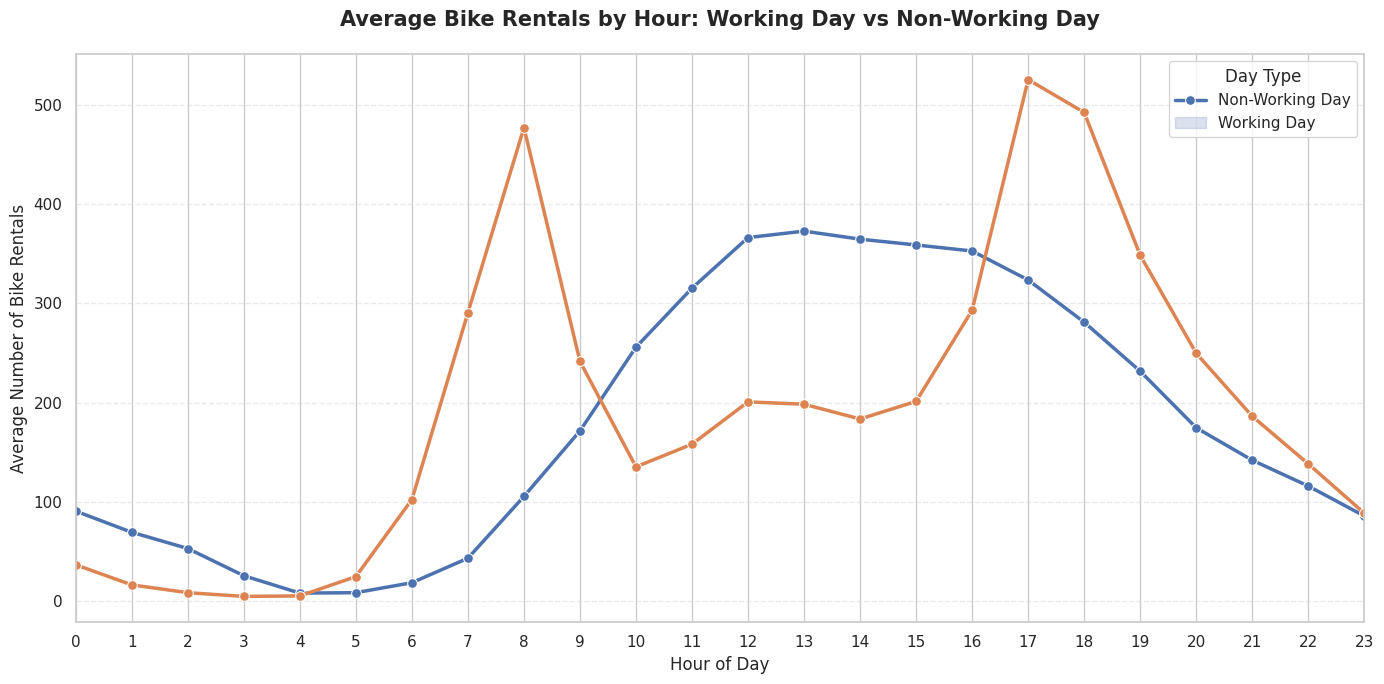

In [19]:

# VISUALISASI 1:
# POLA PENYEWAAN BERDASARKAN JAM DAN JENIS HARI

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=workingday_pattern,
    x='hr',
    y='cnt',
    hue='workingday_label',
    marker='o',
    linewidth=2.5,
    markersize=7
)

# Judul dan label
plt.title(
    'Average Bike Rentals by Hour: Working Day vs Non-Working Day',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Average Number of Bike Rentals', fontsize=12)

# Mengatur sumbu X
plt.xticks(range(24))
plt.xlim(0, 23)

# Mengatur legenda
plt.legend(
    title='Day Type',
    labels=['Non-Working Day', 'Working Day']
)

# Grid dan tata letak
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

plt.show()


### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan musim dan kondisi cuaca selama periode Januari 2011–Desember 2012, serta kombinasi musim dan cuaca apa yang menghasilkan tingkat penyewaan tertinggi dan terendah sebagai dasar penentuan strategi ketersediaan sepeda?

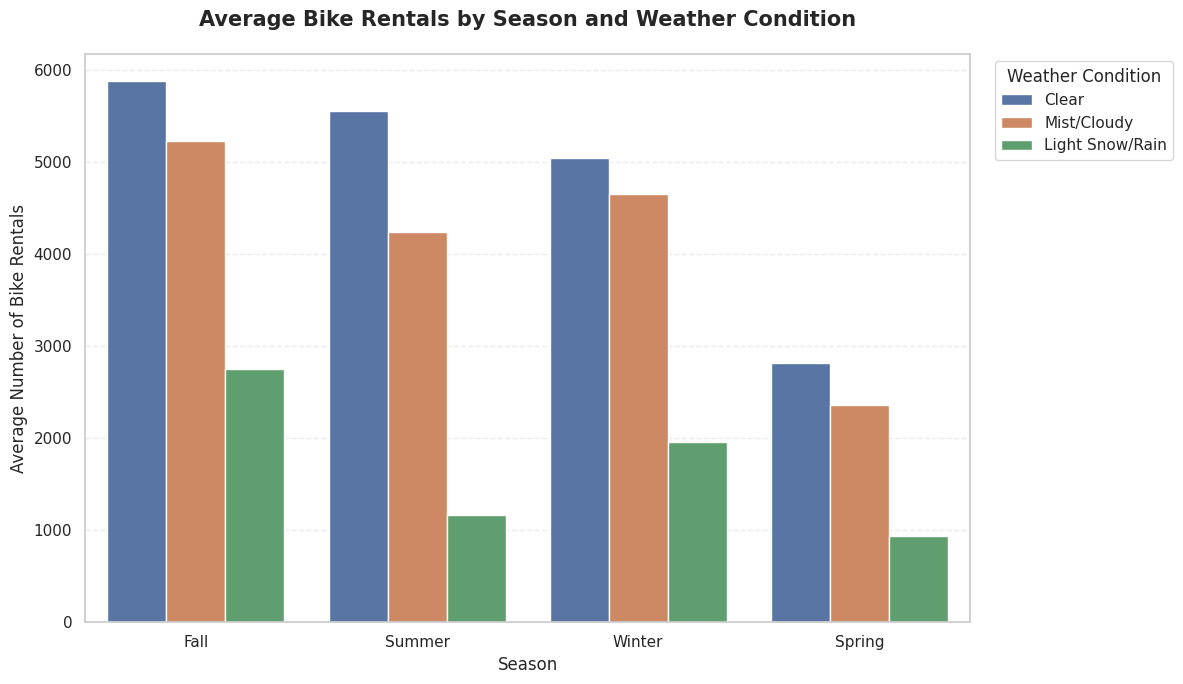

In [20]:

# VISUALISASI 2:
# POLA PENYEWAAN BERDASARKAN MUSIM DAN CUACA

plt.figure(figsize=(12, 7))

sns.barplot(
    data=season_weather,
    x='season_label',
    y='cnt',
    hue='weather_label',
    errorbar=None
)

plt.title(
    'Average Bike Rentals by Season and Weather Condition',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.xlabel('Season', fontsize=12)
plt.ylabel('Average Number of Bike Rentals', fontsize=12)

plt.legend(
    title='Weather Condition',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

plt.show()


**Insight dan Explanatory Analysis:**

**Pertanyaan Bisnis 1: Pola Penyewaan Berdasarkan Waktu**

Berdasarkan visualisasi rata-rata jumlah penyewaan sepeda berdasarkan jam dan jenis hari, ditemukan perbedaan pola permintaan antara working day dan non-working day.

- Pada working day, permintaan penyewaan meningkat pada pagi hari, terutama pukul 07.00–08.00, kemudian kembali meningkat pada sore hari. Puncak permintaan terjadi pada pukul 17.00 dengan rata-rata 525,29 penyewaan per jam.
- Pada non-working day, permintaan cenderung meningkat menjelang siang dan mencapai puncak pada pukul 13.00 dengan rata-rata 372,73 penyewaan per jam.
- Jam 04.00 merupakan waktu dengan rata-rata penyewaan terendah secara keseluruhan, yaitu 6,35 penyewaan per jam.
- Perbedaan pola tersebut mengindikasikan bahwa aktivitas penyewaan pada hari kerja lebih terkonsentrasi pada waktu perjalanan pagi dan sore, sedangkan pada hari non-kerja lebih terkonsentrasi pada siang hari.

**Implikasi Bisnis:** Pengelola layanan Bike Sharing dapat memprioritaskan ketersediaan dan distribusi sepeda pada pukul 07.00–08.00 serta 16.00–18.00 selama hari kerja. Sementara itu, pada hari non-kerja, ketersediaan sepeda dapat lebih diperhatikan pada pukul 10.00–16.00.

**Pertanyaan Bisnis 2: Pola Penyewaan Berdasarkan Musim dan Cuaca**

Berdasarkan visualisasi rata-rata penyewaan sepeda menurut musim dan kondisi cuaca, ditemukan adanya variasi permintaan pada setiap kombinasi musim dan cuaca.

- Musim Fall dengan kondisi cuaca Clear menghasilkan rata-rata penyewaan tertinggi sebesar 5.878,26 sepeda per hari.
- Musim Spring dengan kondisi Light Snow/Rain menghasilkan rata-rata penyewaan terendah sebesar 934,75 sepeda per hari.
- Kondisi Clear menunjukkan rata-rata penyewaan tertinggi pada setiap musim dibandingkan kondisi Mist/Cloudy dan Light Snow/Rain.
- Secara umum, musim Fall dan Summer menunjukkan tingkat penyewaan yang relatif tinggi, sedangkan Spring menunjukkan tingkat penyewaan yang lebih rendah.

**Implikasi Bisnis:** Pengelola dapat mempertimbangkan peningkatan kesiapan armada pada periode dengan permintaan tinggi, khususnya musim Fall dan kondisi cuaca cerah. Sebaliknya, pada kondisi cuaca kurang mendukung, pengelola dapat menyesuaikan distribusi armada berdasarkan pola permintaan aktual.

**Catatan:** Hasil analisis ini bersifat deskriptif dan menunjukkan pola keterkaitan, bukan hubungan sebab-akibat antara musim, cuaca, dan jumlah penyewaan.

## Analisis Lanjutan (Opsional)

### Analisis Lanjutan: Pengelompokan Waktu Menggunakan Teknik Binning

Pada analisis lanjutan ini diterapkan teknik Binning untuk mengelompokkan variabel jam (`hr`) menjadi lima periode waktu, yaitu dini hari, pagi, siang, sore, dan malam.

Pengelompokan dilakukan berdasarkan rentang waktu yang telah ditentukan untuk menyederhanakan analisis pola penyewaan sepeda. Selanjutnya, dilakukan perhitungan rata-rata jumlah penyewaan (`cnt`) pada setiap periode waktu serta perbandingan antara hari kerja (*working day*) dan hari non-kerja (*non-working day*).

Tujuan analisis ini adalah mengidentifikasi periode waktu dengan tingkat permintaan penyewaan tertinggi dan terendah sehingga dapat memberikan informasi tambahan bagi pengelola dalam menentukan prioritas ketersediaan dan distribusi sepeda.

RATA-RATA PENYEWAAN BERDASARKAN PERIODE WAKTU


,time_period,mean,median,min,max,count
3,Sore,362.539938,327.0,7,977,2917
2,Siang,239.033642,212.0,3,776,2913
1,Pagi,208.092210,162.0,1,839,3633
4,Malam,185.806868,155.0,2,743,3640
0,Dini Hari,24.908559,13.0,1,283,4276



PERBANDINGAN PERIODE WAKTU BERDASARKAN JENIS HARI


,workingday_label,time_period,cnt
0,Non-Working Day,Dini Hari,42.998534
1,Non-Working Day,Pagi,119.241110
2,Non-Working Day,Siang,354.738095
3,Non-Working Day,Sore,329.088841
4,Non-Working Day,Malam,150.093043
5,Working Day,Dini Hari,16.435096
6,Working Day,Pagi,249.400806
7,Working Day,Siang,185.282554
8,Working Day,Sore,378.024072
9,Working Day,Malam,202.301205



PERIODE DENGAN PERMINTAAN TERTINGGI
time_period          Sore
mean           362.539938
median              327.0
min                     7
max                   977
count                2917
Name: 3, dtype: object

PERIODE DENGAN PERMINTAAN TERENDAH
time_period    Dini Hari
mean           24.908559
median              13.0
min                    1
max                  283
count               4276
Name: 0, dtype: object


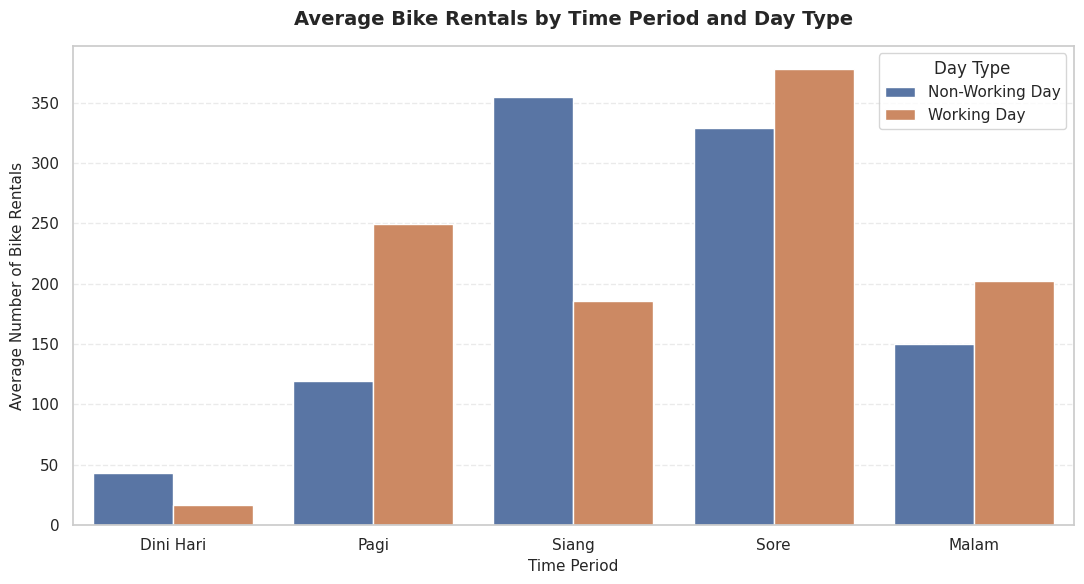

In [21]:

# ANALISIS LANJUTAN: BINNING WAKTU

# 1. Membuat salinan data agar data asli tetap aman
hour_binning = hour_df.copy()

# 2. Menentukan interval waktu
bins = [-1, 5, 10, 14, 18, 23]

labels = [
    'Dini Hari',
    'Pagi',
    'Siang',
    'Sore',
    'Malam'
]

# 3. Melakukan pengelompokan waktu menggunakan pd.cut()
hour_binning['time_period'] = pd.cut(
    hour_binning['hr'],
    bins=bins,
    labels=labels
)

# 4. Menghitung rata-rata penyewaan berdasarkan periode waktu
period_summary = (
    hour_binning.groupby('time_period', observed=False)['cnt']
    .agg(['mean', 'median', 'min', 'max', 'count'])
    .reset_index()
)

period_summary = period_summary.sort_values(
    'mean',
    ascending=False
)

print("RATA-RATA PENYEWAAN BERDASARKAN PERIODE WAKTU")
display(period_summary)

# 5. Membandingkan periode waktu berdasarkan jenis hari
period_comparison = (
    hour_binning.groupby(
        ['workingday_label', 'time_period'],
        observed=False
    )['cnt']
    .mean()
    .reset_index()
)

print("\nPERBANDINGAN PERIODE WAKTU BERDASARKAN JENIS HARI")
display(period_comparison)

# 6. Mengidentifikasi periode dengan permintaan tertinggi
highest_period = period_summary.loc[
    period_summary['mean'].idxmax()
]

lowest_period = period_summary.loc[
    period_summary['mean'].idxmin()
]

print("\nPERIODE DENGAN PERMINTAAN TERTINGGI")
print(highest_period)

print("\nPERIODE DENGAN PERMINTAAN TERENDAH")
print(lowest_period)

# 7. Visualisasi hasil binning
plt.figure(figsize=(11, 6))

sns.barplot(
    data=period_comparison,
    x='time_period',
    y='cnt',
    hue='workingday_label',
    errorbar=None
)

plt.title(
    'Average Bike Rentals by Time Period and Day Type',
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.xlabel('Time Period', fontsize=11)
plt.ylabel('Average Number of Bike Rentals', fontsize=11)

plt.legend(title='Day Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Insight Analisis Lanjutan: Binning Periode Waktu

- Hasil pengelompokan waktu menunjukkan bahwa periode sore memiliki rata-rata penyewaan tertinggi sebesar **362,54 sepeda**, sedangkan periode dini hari memiliki rata-rata terendah sebesar **24,91 sepeda**.
- Pada hari kerja (*working day*), permintaan penyewaan tertinggi terjadi pada periode sore sebesar **378,02 sepeda**, diikuti periode pagi sebesar **249,40 sepeda**. Pola tersebut menunjukkan bahwa peningkatan penyewaan pada hari kerja terjadi pada periode pagi dan sore, yang sejalan dengan kemungkinan tingginya aktivitas perjalanan masyarakat pada waktu berangkat dan pulang kerja.
- Pada hari non-kerja (*non-working day*), permintaan tertinggi terjadi pada periode siang sebesar **354,74 sepeda**, kemudian sore sebesar **329,09 sepeda**. Pola ini menunjukkan bahwa aktivitas penyewaan pada hari non-kerja lebih terkonsentrasi pada siang hingga sore hari.
- Secara keseluruhan, hasil Binning memperlihatkan bahwa pola permintaan penyewaan berbeda berdasarkan jenis hari. Oleh karena itu, pengelola perlu mempertimbangkan perbedaan pola tersebut dalam menentukan waktu prioritas ketersediaan dan distribusi sepeda.

Hasil analisis Binning memperkuat temuan pada analisis berdasarkan jam, yaitu bahwa waktu dengan permintaan penyewaan tertinggi berbeda antara hari kerja dan hari non-kerja. Pengelompokan periode waktu ini memberikan gambaran yang lebih sederhana bagi pengelola dalam menentukan prioritas ketersediaan sepeda.

## Conclusion & Recommendation

Bagian ini menyajikan kesimpulan berdasarkan hasil analisis data, Exploratory Data Analysis (EDA), visualisasi, serta analisis lanjutan menggunakan teknik Binning pada Bike Sharing Dataset periode Januari 2011 hingga Desember 2012. Kesimpulan disusun untuk menjawab pertanyaan bisnis yang telah dirumuskan sebelumnya, sedangkan rekomendasi diberikan sebagai dasar pertimbangan pengambilan keputusan operasional bagi pengelola layanan Bike Sharing.

###Conclusion (Kesimpulan)

### Kesimpulan Pertanyaan Bisnis 1: Pola Penyewaan Berdasarkan Waktu

Berdasarkan hasil Exploratory Data Analysis dan visualisasi, ditemukan adanya perbedaan pola penyewaan sepeda antara hari kerja (*working day*) dan hari non-kerja (*non-working day*).

Pada hari kerja, permintaan penyewaan mengalami peningkatan pada pagi hari, khususnya pukul 07.00–08.00, dan mencapai puncak pada pukul 17.00 dengan rata-rata 525,29 penyewaan per jam. Sementara itu, pada hari non-kerja, permintaan cenderung meningkat menjelang siang dan mencapai puncak pada pukul 13.00 dengan rata-rata 372,73 penyewaan per jam.

Secara keseluruhan, rata-rata penyewaan terendah terjadi pada pukul 04.00 sebesar 6,35 penyewaan per jam.

Hasil analisis lanjutan menggunakan teknik Binning juga memperkuat temuan tersebut. Periode sore memiliki rata-rata penyewaan tertinggi secara keseluruhan sebesar 362,54, sedangkan periode dini hari memiliki rata-rata terendah sebesar 24,91 penyewaan per jam. Pada hari kerja, periode sore menunjukkan rata-rata penyewaan tertinggi sebesar 378,02, sedangkan pada hari non-kerja, periode siang menjadi periode dengan rata-rata penyewaan tertinggi sebesar 354,74.

Dengan demikian, pola penyewaan sepeda memiliki karakteristik waktu yang berbeda berdasarkan jenis hari. Hari kerja menunjukkan konsentrasi permintaan pada pagi dan sore hari, sedangkan hari non-kerja cenderung memiliki permintaan lebih tinggi pada siang hingga sore hari.

### Kesimpulan Pertanyaan Bisnis 2: Pola Penyewaan Berdasarkan Musim dan Cuaca

Berdasarkan hasil analisis dan visualisasi, jumlah penyewaan sepeda menunjukkan variasi berdasarkan musim dan kondisi cuaca.

Musim Fall memiliki rata-rata penyewaan tertinggi sebesar 5.644,30 sepeda per hari, sedangkan Spring memiliki rata-rata terendah sebesar 2.604,13 sepeda per hari.

Berdasarkan kondisi cuaca, Clear menunjukkan rata-rata penyewaan tertinggi sebesar 4.876,79 sepeda per hari. Sebaliknya, kondisi Light Snow/Rain memiliki rata-rata terendah sebesar 1.803,29 sepeda per hari.

Hasil analisis kombinasi musim dan cuaca juga menunjukkan bahwa Fall dengan kondisi Clear menghasilkan rata-rata penyewaan tertinggi sebesar 5.878,26 sepeda per hari. Sementara itu, Spring dengan kondisi Light Snow/Rain menghasilkan rata-rata terendah sebesar 934,75 sepeda per hari.

Dengan demikian, pola penyewaan sepeda menunjukkan variasi berdasarkan musim dan kondisi cuaca. Musim Fall dan kondisi cuaca Clear cenderung berkaitan dengan tingkat penyewaan yang lebih tinggi, sedangkan Spring dan kondisi Light Snow/Rain menunjukkan tingkat penyewaan yang relatif lebih rendah.

Perlu diperhatikan bahwa kategori Light Snow/Rain pada dataset harian hanya memiliki 21 observasi, jauh lebih sedikit dibandingkan kategori Clear yang memiliki 463 observasi. Oleh karena itu, hasil rata-rata pada kategori Light Snow/Rain perlu diinterpretasikan secara hati-hati.



**Keterbatasan Analisis**

Analisis ini menggunakan data historis Bike Sharing selama periode Januari 2011 hingga Desember 2012. Oleh karena itu, pola yang ditemukan menggambarkan karakteristik penyewaan pada periode pengamatan tersebut dan belum tentu sepenuhnya mencerminkan kondisi permintaan pada periode saat ini.

Selain itu, analisis yang dilakukan bersifat deskriptif sehingga temuan mengenai perbedaan penyewaan berdasarkan waktu, musim, dan kondisi cuaca menunjukkan pola keterkaitan, bukan hubungan sebab-akibat. Jumlah observasi pada beberapa kategori cuaca juga tidak seimbang, sehingga hasil perbandingan perlu diinterpretasikan secara proporsional.

Meskipun demikian, hasil analisis ini dapat memberikan gambaran awal mengenai karakteristik permintaan penyewaan sepeda dan menjadi dasar pertimbangan dalam penyusunan strategi operasional layanan Bike Sharing.



###Rekomendasi Action Item:

Berdasarkan hasil analisis yang telah dilakukan, berikut beberapa rekomendasi tindakan (*action items*) yang dapat dipertimbangkan oleh pengelola layanan Bike Sharing:

1. **Optimalisasi ketersediaan sepeda berdasarkan waktu**

   Pengelola disarankan memprioritaskan ketersediaan dan distribusi sepeda pada pukul 07.00–08.00 dan 16.00–18.00 selama hari kerja. Pada hari non-kerja, perhatian dapat difokuskan pada periode pukul 10.00–16.00 karena menunjukkan tingkat permintaan yang relatif tinggi. Penyesuaian ini diharapkan dapat membantu mengurangi ketidakseimbangan ketersediaan sepeda pada jam-jam dengan permintaan tinggi.

2. **Penyesuaian kapasitas armada berdasarkan musim dan cuaca**

   Pengelola dapat mempertimbangkan peningkatan kesiapan armada pada periode dengan permintaan tinggi, khususnya musim Fall dan kondisi cuaca Clear. Sebaliknya, ketika kondisi cuaca kurang mendukung, pengelola dapat menyesuaikan distribusi sepeda berdasarkan pola permintaan aktual dan informasi prakiraan cuaca.

3. **Evaluasi dan monitoring permintaan secara berkala**

   Pengelola disarankan melakukan pemantauan pola penyewaan berdasarkan jam, jenis hari, musim, dan kondisi cuaca secara berkala. Hasil pemantauan dapat digunakan untuk mengevaluasi efektivitas distribusi armada serta memperbarui strategi operasional sesuai perubahan pola permintaan.